Aflevering 3

zvp380/Josefine Rosenfeldt

8.oktober

In [178]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('cars.csv')
pd.set_option('display.float_format', '{:.5f}'.format)
df.describe(percentiles=[]).T

,count,mean,std,min,50%,max
year,9694.00000,2001.09676,11.07696,1980.00000,2002.00000,2018.00000
product_id,9694.00000,486.67495,278.99753,0.00000,512.00000,1066.00000
sales,9694.00000,59103.39104,86940.25408,10.00000,27394.00000,891482.00000
number_households,9694.00000,107213264.90613,13932786.27747,80780000.00000,109300000.00000,127590000.00000
price,9694.00000,36.04769,17.12656,11.14478,31.82023,99.98639
height,9694.00000,60.94814,8.41152,43.50000,57.70000,107.50000
footprint,9694.00000,13392.63000,1968.91519,6514.54000,13330.06400,21821.85900
weight,9694.00000,3561.21114,897.76553,1113.00000,3470.50000,8550.00000
hp,9694.00000,192.18197,83.88244,44.00000,175.00000,645.00000
mpg,9694.00000,20.93615,6.58300,10.00000,19.00000,50.00000


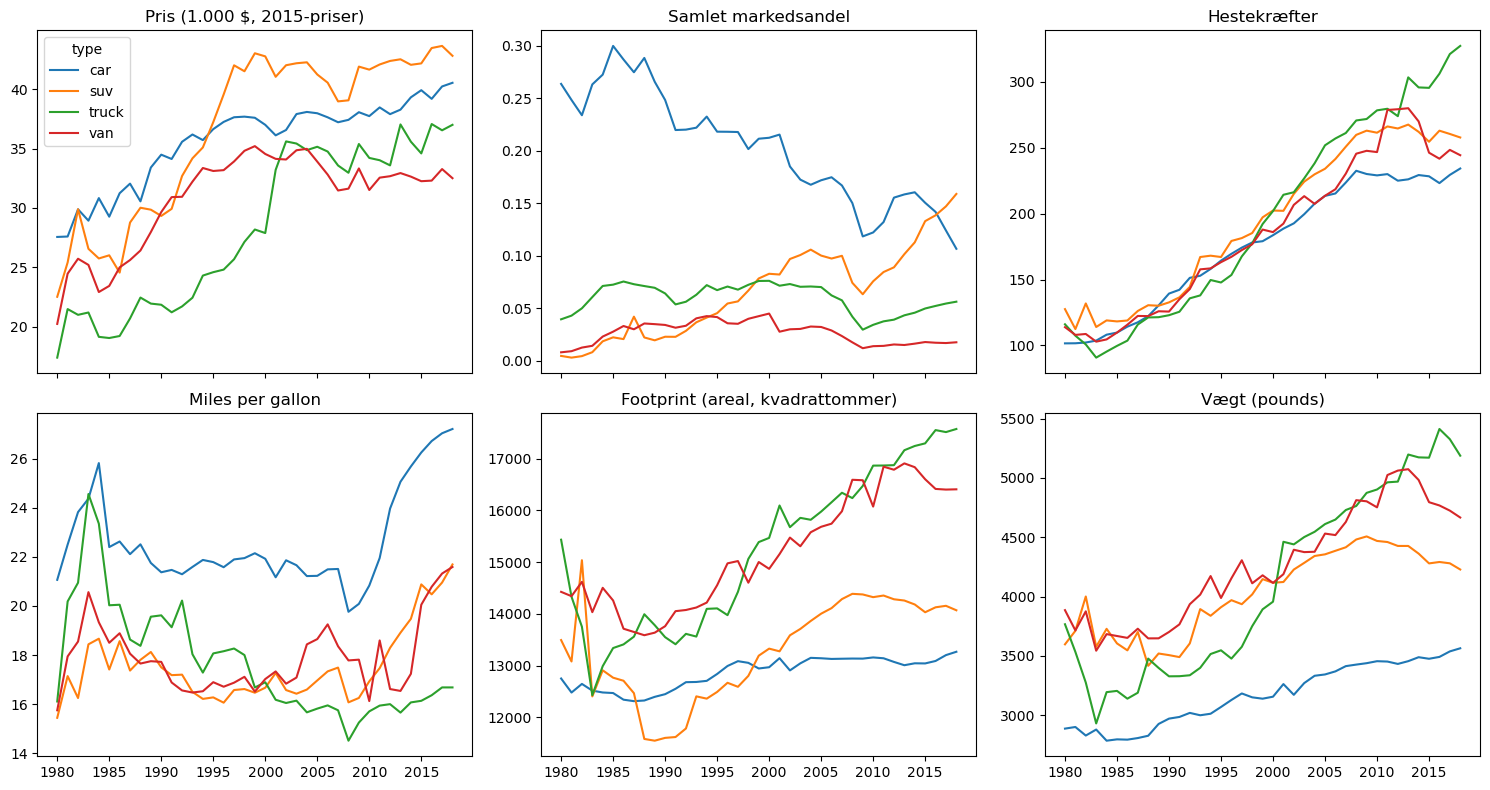

In [179]:
#1A

import matplotlib.pyplot as plt
import seaborn as sns

# Én variabel for biltype ud fra de gensidigt udelukkende dummies
types = ['car', 'suv', 'truck', 'van']
df['type'] = df[types].idxmax(axis=1)

# Gennemsnit pr. år og biltype
vars_mean = ['price', 'hp', 'mpg', 'footprint', 'weight']
by_year = df.groupby(['year', 'type'])[vars_mean].mean().reset_index()

# Samlet markedsandel pr. år og biltype
share = df.groupby(['year', 'type'])['market_share'].sum().reset_index()

labels = {
    'price': 'Pris (1.000 $, 2015-priser)',
    'market_share': 'Samlet markedsandel',
    'hp': 'Hestekræfter',
    'mpg': 'Miles per gallon',
    'footprint': 'Footprint (areal, kvadrattommer)',
    'weight': 'Vægt (pounds)',
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for ax, var in zip(axes.flat, labels):
    data = share if var == 'market_share' else by_year
    sns.lineplot(data=data, x='year', y=var, hue='type', ax=ax,
                 legend='auto' if var == 'price' else False)
    ax.set_title(labels[var])
    ax.set_xlabel('')
    ax.set_ylabel('')
fig.tight_layout()
plt.savefig('fig_1a_tid.png', dpi=300, bbox_inches='tight')
plt.show()



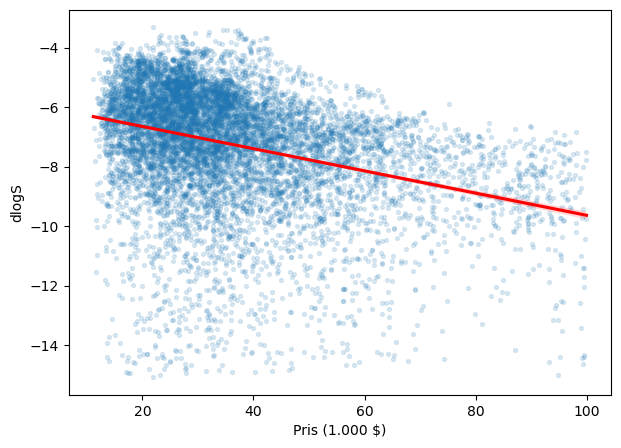

In [180]:
#1A

fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(data=df, x='price', y='dlogS', ax=ax,
            scatter_kws={'alpha': 0.15, 's': 8}, line_kws={'color': 'red'})
ax.set_xlabel('Pris (1.000 $)')
ax.set_ylabel('dlogS')
plt.savefig('fig_1a_dlogS_pris.png', dpi=300, bbox_inches='tight')
plt.show()


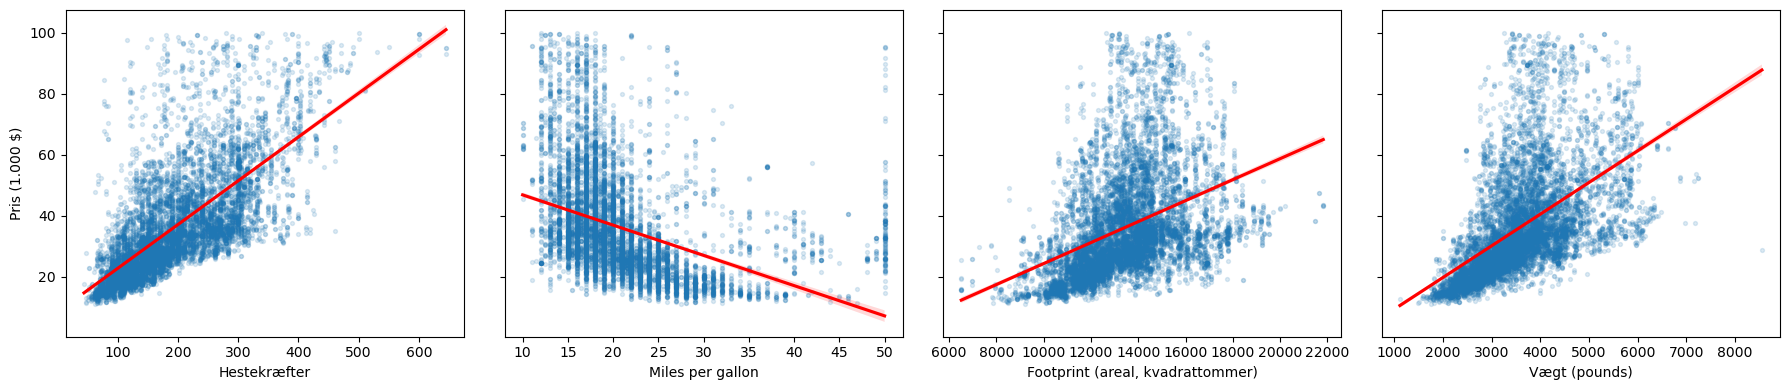

In [181]:
#1A

attrs = ['hp', 'mpg', 'footprint', 'weight']
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, var in zip(axes, attrs):
    sns.regplot(data=df, x=var, y='price', ax=ax,
                scatter_kws={'alpha': 0.15, 's': 8}, line_kws={'color': 'red'})
    ax.set_xlabel(labels[var])
    ax.set_ylabel('Pris (1.000 $)' if var == 'hp' else '')
fig.tight_layout()
plt.savefig('fig_1a_pris_egenskaber.png', dpi=300, bbox_inches='tight')
plt.show()


In [182]:
#1B - Specifikation 1

df['const'] = 1 #tilføjer en konstant
X = df[['const', 'price']].values #forklarende variable
y = df['dlogS'].values

n = X.shape[0] #antal rækker = 9694
k = X.shape[1] - 1  # antal forklarende variable (kolonner) (ikke inkl. konstant)

alpha_hat = np.linalg.inv(X.T @ X) @ X.T @ y # alpha_hat[0] = beta_0, alpha_hat[1] = alpha_hat

y_hat = X @ alpha_hat
residualer = y - y_hat

TSS = np.sum((y - y.mean())**2)        # total sum of squares
ESS = np.sum((y_hat - y.mean())**2)    # explained sum of squares
RSS = np.sum(residualer**2)            # sum of squared residuals
R2 = ESS / TSS

sigma2_hat = RSS/(n-k-1)
se_alpha = np.sqrt(np.diag(sigma2_hat * np.linalg.inv(X.T @ X))) #standarderror

print(f"beta_0: estimat = {alpha_hat[0]:.4f}, std. fejl = {se_alpha[0]:.4f}")
print(f"alpha_hat: estimat = {alpha_hat[1]:.4f}, std. fejl = {se_alpha[1]:.4f}")
print(f"TSS = {TSS:.2f}")
print(f"ESS = {ESS:.2f}")
print(f"RSS = {RSS:.2f}")
print(f"R2 = {R2:.4f}")

alpha_hat1, se_alpha1 = alpha_hat, se_alpha #omdøber, så de kan bruges til 1C

beta_0: estimat = -5.9072, std. fejl = 0.0439
alpha_hat: estimat = -0.0373, std. fejl = 0.0011
TSS = 37300.70
ESS = 3961.22
RSS = 33339.47
R2 = 0.1062


In [204]:
#1B - Specifikation 2

#Dummies
df['sport'] = (df['sport'] == 1).astype(int)
df['EV'] = (df['EV'] == 1).astype(int)
df['truck'] = (df['truck'] == 1).astype(int)
df['suv'] = (df['suv'] == 1).astype(int)
df['van'] = (df['van'] == 1).astype(int)

x = ['const', 'price', 'hp', 'mpg', 'height', 'footprint', 'weight', 'number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van']

X = df[x].values #forklarende variable
y = df['dlogS'].values

n = X.shape[0] #antal rækker = 9694
k = X.shape[1] - 1  # antal forklarende variable (kolonner) (ikke inkl. konstant)

alpha_hat = np.linalg.inv(X.T @ X) @ X.T @ y # alpha_hat[0] = beta_0, alpha_hat[1] = alpha_hat

y_hat = X @ alpha_hat
residualer = y - y_hat

TSS = np.sum((y - y.mean())**2)        # total sum of squares
ESS = np.sum((y_hat - y.mean())**2)    # explained sum of squares
RSS = np.sum(residualer**2)            # sum of squared residuals
R2 = ESS / TSS

sigma2_hat = RSS/(n-k-1)
se_alpha = np.sqrt(np.diag(sigma2_hat * np.linalg.inv(X.T @ X))) #standarderror

print("\nEstimater for alle forklarende variable:")
for navn, b, se in zip(x, alpha_hat, se_alpha):
    if not navn.startswith(('y_', 'm_')):
        print(f"{navn:18s} estimat = {b:9.4f}, std. fejl = {se:.4f}, t = {b/se:.2f}")

print(f"TSS = {TSS:.2f}")
print(f"ESS = {ESS:.2f}")
print(f"RSS = {RSS:.2f}")
print(f"R2 = {R2:.4f}")

alpha_hat2, se_alpha2 = alpha_hat, se_alpha #omdøber, så de kan bruges til 1C


Estimater for alle forklarende variable:
const              estimat =   -5.4138, std. fejl = 0.2908, t = -18.62
price              estimat =   -0.0243, std. fejl = 0.0016, t = -15.06
hp                 estimat =   -0.0038, std. fejl = 0.0004, t = -10.18
mpg                estimat =   -0.0427, std. fejl = 0.0037, t = -11.67
height             estimat =   -0.0237, std. fejl = 0.0048, t = -4.90
footprint          estimat =    0.0004, std. fejl = 0.0000, t = 19.12
weight             estimat =   -0.0007, std. fejl = 0.0001, t = -10.94
number_trims       estimat =    0.0552, std. fejl = 0.0019, t = 29.19
releaseYear        estimat =   -1.0643, std. fejl = 0.0614, t = -17.32
yearsSinceDesign   estimat =   -0.1269, std. fejl = 0.0059, t = -21.52
sport              estimat =   -0.6144, std. fejl = 0.0631, t = -9.74
EV                 estimat =   -0.6321, std. fejl = 0.2060, t = -3.07
truck              estimat =   -0.1571, std. fejl = 0.0854, t = -1.84
suv                estimat =    0.8794, s

In [205]:
#1B - Specifikation 3

#Fjern gamle dummyer
df = df.drop(columns=[c for c in df.columns if c.startswith('y_')])

#Add dummies for 'year'
year_dummies = pd.get_dummies(df['year'], prefix = 'y', drop_first =True, dtype=int)
df = pd.concat([df, year_dummies], axis=1)

#Store year variable names for later use
years = list(year_dummies.columns) #['y_1981', 'y_1982'...]

x = ['const', 'price', 'hp', 'mpg', 'height', 'footprint', 'weight', 
     'number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van'] + years

X = df[x].values #forklarende variable
y = df['dlogS'].values

n = X.shape[0] #antal rækker = 9694
k = X.shape[1] - 1  # antal forklarende variable (kolonner) (ikke inkl. konstant)

alpha_hat = np.linalg.inv(X.T @ X) @ X.T @ y # alpha_hat[0] = beta_0, alpha_hat[1] = alpha_hat

y_hat = X @ alpha_hat
residualer = y - y_hat

TSS = np.sum((y - y.mean())**2)        # total sum of squares
ESS = np.sum((y_hat - y.mean())**2)    # explained sum of squares
RSS = np.sum(residualer**2)            # sum of squared residuals
R2 = ESS / TSS

sigma2_hat = RSS/(n-k-1)
se_alpha = np.sqrt(np.diag(sigma2_hat * np.linalg.inv(X.T @ X))) #standarderror

print("\nEstimater for alle forklarende variable:")
for navn, b, se in zip(x, alpha_hat, se_alpha):
    if not navn.startswith(('y_', 'm_')):
        print(f"{navn:18s} estimat = {b:9.4f}, std. fejl = {se:.4f}, t = {b/se:.2f}")

print(f"TSS = {TSS:.2f}")
print(f"ESS = {ESS:.2f}")
print(f"RSS = {RSS:.2f}")
print(f"R2 = {R2:.4f}")

alpha_hat3, se_alpha3 = alpha_hat, se_alpha #omdøber, så de kan bruges til 1C


Estimater for alle forklarende variable:
const              estimat =   -6.8066, std. fejl = 0.3177, t = -21.42
price              estimat =   -0.0370, std. fejl = 0.0017, t = -21.90
hp                 estimat =    0.0024, std. fejl = 0.0005, t = 4.88
mpg                estimat =   -0.0115, std. fejl = 0.0042, t = -2.72
height             estimat =   -0.0154, std. fejl = 0.0047, t = -3.24
footprint          estimat =    0.0003, std. fejl = 0.0000, t = 16.62
weight             estimat =   -0.0006, std. fejl = 0.0001, t = -9.02
number_trims       estimat =    0.0530, std. fejl = 0.0018, t = 28.64
releaseYear        estimat =   -1.2272, std. fejl = 0.0608, t = -20.18
yearsSinceDesign   estimat =   -0.1278, std. fejl = 0.0058, t = -22.06
sport              estimat =   -0.6522, std. fejl = 0.0618, t = -10.55
EV                 estimat =   -0.7759, std. fejl = 0.2010, t = -3.86
truck              estimat =   -0.3225, std. fejl = 0.0835, t = -3.86
suv                estimat =    0.8557, std.

In [206]:
#1B - Specifikation 4

#Fjern gamle dummyer
df = df.drop(columns=[c for c in df.columns if c.startswith('y_')])

#Add dummies for 'year'
year_dummies = pd.get_dummies(df['year'], prefix = 'y', drop_first =True, dtype=int)
df = pd.concat([df, year_dummies], axis=1)

#Store year variable names for later use
years = list(year_dummies.columns) #['y_1981', 'y_1982'...]

df['log_hp'] = np.log(df['hp'])
df['log_mpg'] = np.log(df['mpg'])
df['log_height'] = np.log(df['height'])
df['log_footprint'] = np.log(df['footprint'])
df['log_weight'] = np.log(df['weight'])
df['log_number_trims'] = np.log(df['number_trims'])

x = ['const', 'price', 'log_hp', 'log_mpg', 'log_height', 'log_footprint', 'log_weight', 
     'log_number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van'] + years

X = df[x].values #forklarende variable
y = df['dlogS'].values

n = X.shape[0] #antal rækker = 9694
k = X.shape[1] - 1  # antal forklarende variable (kolonner) (ikke inkl. konstant)

alpha_hat = np.linalg.inv(X.T @ X) @ X.T @ y # alpha_hat[0] = beta_0, alpha_hat[1] = alpha_hat

y_hat = X @ alpha_hat
residualer = y - y_hat

TSS = np.sum((y - y.mean())**2)        # total sum of squares
ESS = np.sum((y_hat - y.mean())**2)    # explained sum of squares
RSS = np.sum(residualer**2)            # sum of squared residuals
R2 = ESS / TSS

sigma2_hat = RSS/(n-k-1)
se_alpha = np.sqrt(np.diag(sigma2_hat * np.linalg.inv(X.T @ X))) #standarderror


print("\nEstimater for alle forklarende variable:")
for navn, b, se in zip(x, alpha_hat, se_alpha):
    if not navn.startswith(('y_', 'm_')):
        print(f"{navn:18s} estimat = {b:9.4f}, std. fejl = {se:.4f}, t = {b/se:.2f}")

print(f"TSS = {TSS:.2f}")
print(f"ESS = {ESS:.2f}")
print(f"RSS = {RSS:.2f}")
print(f"R2 = {R2:.4f}")

alpha_hat4, se_alpha4 = alpha_hat, se_alpha #omdøber, så de kan bruges til 1C


Estimater for alle forklarende variable:
const              estimat =  -25.4344, std. fejl = 1.6540, t = -15.38
price              estimat =   -0.0298, std. fejl = 0.0014, t = -20.97
log_hp             estimat =    0.4285, std. fejl = 0.0994, t = 4.31
log_mpg            estimat =    0.3280, std. fejl = 0.1079, t = 3.04
log_height         estimat =   -1.2168, std. fejl = 0.2632, t = -4.62
log_footprint      estimat =    2.9136, std. fejl = 0.2203, t = 13.22
log_weight         estimat =   -0.8093, std. fejl = 0.2115, t = -3.83
log_number_trims   estimat =    1.1869, std. fejl = 0.0181, t = 65.44
releaseYear        estimat =   -0.5031, std. fejl = 0.0542, t = -9.28
yearsSinceDesign   estimat =   -0.1077, std. fejl = 0.0050, t = -21.35
sport              estimat =   -0.5040, std. fejl = 0.0547, t = -9.21
EV                 estimat =   -0.9254, std. fejl = 0.1688, t = -5.48
truck              estimat =   -0.6029, std. fejl = 0.0723, t = -8.34
suv                estimat =    0.5931, std. fe

In [186]:
#1C 

#t-værdier
t1 = alpha_hat1[1] / se_alpha1[1]
t2 = alpha_hat2[1] / se_alpha2[1]
t3 = alpha_hat3[1] / se_alpha3[1]
t4 = alpha_hat4[1] / se_alpha4[1]

print(f"Specifikation 1: t = {t1:.2f}")
print(f"Specifikation 2: t = {t2:.2f}")
print(f"Specifikation 3: t = {t3:.2f}")
print(f"Specifikation 4: t = {t4:.2f}")

Specifikation 1: t = -33.93
Specifikation 2: t = -15.06
Specifikation 3: t = -21.90
Specifikation 4: t = -20.97


In [187]:
#2A - make-dummies

df = df.drop(columns=[c for c in df.columns if c.startswith('m_')]) #Fjern gamle make-dummies
df = df.drop(columns=[c for c in df.columns if c.startswith('y_')]) #Fjern gamle tids-dummies

#Add dummies for 'make' (bilmærke)
make_dummies = pd.get_dummies(df['make'], prefix = 'm', drop_first =True, dtype=int)
df = pd.concat([df, make_dummies], axis=1)

#Store brand variable names for later use
brand = list(make_dummies.columns) #['m_toyota', 'm_audi'...]

#Add dummies for 'year'
year_dummies = pd.get_dummies(df['year'], prefix = 'y', drop_first =True, dtype=int)
df = pd.concat([df, year_dummies], axis=1)

#Store year variable names for later use
years = list(year_dummies.columns) #['y_1981', 'y_1982'...]

df['log_hp'] = np.log(df['hp'])
df['log_mpg'] = np.log(df['mpg'])
df['log_height'] = np.log(df['height'])
df['log_footprint'] = np.log(df['footprint'])
df['log_weight'] = np.log(df['weight'])
df['log_number_trims'] = np.log(df['number_trims'])

x = ['const', 'price', 'log_hp', 'log_mpg', 'log_height', 'log_footprint', 'log_weight', 
     'log_number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van'] + years + brand

X = df[x].values #forklarende variable
y = df['dlogS'].values

n = X.shape[0] #antal rækker = 9694
k = X.shape[1] - 1  # antal forklarende variable (kolonner) (ikke inkl. konstant)

alpha_hat = np.linalg.inv(X.T @ X) @ X.T @ y # alpha_hat[0] = beta_0, alpha_hat[1] = alpha_hat

y_hat = X @ alpha_hat
residualer = y - y_hat

TSS = np.sum((y - y.mean())**2)        # total sum of squares
ESS = np.sum((y_hat - y.mean())**2)    # explained sum of squares
RSS = np.sum(residualer**2)            # sum of squared residuals
R2 = ESS / TSS

sigma2_hat = RSS/(n-k-1)
se_alpha = np.sqrt(np.diag(sigma2_hat * np.linalg.inv(X.T @ X))) #standarderror

print(f"beta_0: estimat = {alpha_hat[0]:.4f}, std. fejl = {se_alpha[0]:.4f}")
print(f"alpha_hat: estimat = {alpha_hat[1]:.4f}, std. fejl = {se_alpha[1]:.4f}")
print(f"TSS = {TSS:.2f}")
print(f"ESS = {ESS:.2f}")
print(f"RSS = {RSS:.2f}")
print(f"R2 = {R2:.4f}")


beta_0: estimat = -15.1108, std. fejl = 1.7284
alpha_hat: estimat = -0.0337, std. fejl = 0.0017
TSS = 37300.70
ESS = 21967.19
RSS = 15333.51
R2 = 0.5889


In [188]:
#2A - within-transformation

df = df.drop(columns=[c for c in df.columns if c.startswith('m_')]) #Fjern gamle make-dummies
df = df.drop(columns=[c for c in df.columns if c.startswith('y_')]) #Fjern gamle tids-dummies

#Add dummies for 'year'
year_dummies = pd.get_dummies(df['year'], prefix = 'y', drop_first =True, dtype=int)
df = pd.concat([df, year_dummies], axis=1)
#Store year variable names for later use
years = list(year_dummies.columns) #['y_1981', 'y_1982'...]

#within-transformation
df_within = df.copy()
vars_to_transform = ['dlogS', 'price', 'log_hp', 'log_mpg', 'log_height', 'log_footprint',
                     'log_weight', 'log_number_trims', 'releaseYear', 'yearsSinceDesign',
                     'sport', 'EV', 'truck', 'suv', 'van'] + years

for var in vars_to_transform:
    make_mean = df.groupby('make')[var].transform('mean')
    df_within[var] = df[var] - make_mean

X = df_within[vars_to_transform[1:]].values #alle variable undtagem dlogS
y = df_within['dlogS'].values

n = X.shape[0] #antal rækker = 9694
k = X.shape[1]  # antal forklarende variable (kolonner) (ingen konstant)

alpha_hat = np.linalg.inv(X.T @ X) @ X.T @ y # alpha_hat[0] = alpha_hat

y_hat = X @ alpha_hat
residualer = y - y_hat

TSS = np.sum((y - y.mean())**2)        # total sum of squares
ESS = np.sum((y_hat - y.mean())**2)    # explained sum of squares
RSS = np.sum(residualer**2)            # sum of squared residuals
R2 = ESS / TSS

sigma2_hat = RSS/(n-k)
se_alpha = np.sqrt(np.diag(sigma2_hat * np.linalg.inv(X.T @ X))) #standarderror

print(f"alpha_hat: estimat = {alpha_hat[0]:.4f}, std. fejl = {se_alpha[0]:.4f}")
print(f"TSS = {TSS:.2f}")
print(f"ESS = {ESS:.2f}")
print(f"RSS = {RSS:.2f}")
print(f"R2 = {R2:.4f}")


alpha_hat: estimat = -0.0337, std. fejl = 0.0017
TSS = 30415.61
ESS = 15082.11
RSS = 15333.51
R2 = 0.4959


In [208]:
#2C - first stage i 2SLS

# Make-dummies (genskabes, da within-cellen fjerner dem)
df = df.drop(columns=[c for c in df.columns if c.startswith('m_')]) #Fjern gamle make-dummies
make_dummies = pd.get_dummies(df['make'], prefix = 'm', drop_first =True, dtype=int)
df = pd.concat([df, make_dummies], axis=1)
brand = list(make_dummies.columns)

x = ['const', 'RXR', 'log_hp', 'log_mpg', 'log_height', 'log_footprint', 'log_weight',
     'log_number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van'] + years + brand

X = df[x].values
y = df['price'].values  # prisen er den afhængige variabel

n = X.shape[0]
k = X.shape[1] - 1

gamma1_hat = np.linalg.inv(X.T @ X) @ X.T @ y   # gamma_hat[1] = gamma_1 (RXR)

residualer = y - X @ gamma1_hat
RSS = np.sum(residualer**2)
sigma2_hat = RSS / (n - k - 1)
se_gamma1 = np.sqrt(np.diag(sigma2_hat * np.linalg.inv(X.T @ X)))

t_gamma1 = gamma1_hat[1] / se_gamma1[1]

print(f"gamma_1 (RXR): estimat = {gamma1_hat[1]:.4f}, std. fejl = {se_gamma1[1]:.4f}, t = {t_gamma1:.2f}")

print("\nEstimater for alle forklarende variable (first stage):")
for navn, b, se in zip(x, gamma1_hat, se_gamma1):
    if not navn.startswith(('y_', 'm_')):
        print(f"{navn:18s} estimat = {b:9.4f}, std. fejl = {se:.4f}, t = {b/se:.2f}")

gamma_1 (RXR): estimat = 4.1465, std. fejl = 0.5157, t = 8.04

Estimater for alle forklarende variable (first stage):
const              estimat = -196.1827, std. fejl = 9.9793, t = -19.66
RXR                estimat =    4.1465, std. fejl = 0.5157, t = 8.04
log_hp             estimat =   16.6868, std. fejl = 0.5301, t = 31.48
log_mpg            estimat =    5.0653, std. fejl = 0.6107, t = 8.29
log_height         estimat =  -16.0567, std. fejl = 1.4870, t = -10.80
log_footprint      estimat =   -8.3816, std. fejl = 1.3338, t = -6.28
log_weight         estimat =   34.2229, std. fejl = 1.1336, t = 30.19
log_number_trims   estimat =   -1.3418, std. fejl = 0.1010, t = -13.28
releaseYear        estimat =   -0.7578, std. fejl = 0.2931, t = -2.59
yearsSinceDesign   estimat =    0.0038, std. fejl = 0.0279, t = 0.14
sport              estimat =    4.9603, std. fejl = 0.3051, t = 16.26
EV                 estimat =    6.4715, std. fejl = 0.9778, t = 6.62
truck              estimat =   -4.0889, std

In [210]:
#2C - Second stage i 2SLS

# Forudsagt pris fra first stage
df['price_hat'] = X @ gamma1_hat

# Samme variable som i efterspørgselsligningen, men med price_hat
x2 = ['const', 'price_hat', 'log_hp', 'log_mpg', 'log_height', 'log_footprint', 'log_weight',
      'log_number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van'] + years + brand

X_hat = df[x2].values
y = df['dlogS'].values

n = X_hat.shape[0]
k = X_hat.shape[1] - 1

alpha_hat_iv = np.linalg.inv(X_hat.T @ X_hat) @ X_hat.T @ y   # alpha_hat_iv[1] = alpha

# Residualer beregnes med den FAKTISKE pris (ikke price_hat)
x_true = ['const', 'price'] + x2[2:]
X_true = df[x_true].values
residualer_iv = y - X_true @ alpha_hat_iv

RSS_iv = np.sum(residualer_iv**2)
sigma2_hat_iv = RSS_iv / (n - k - 1)
se_alpha_iv = np.sqrt(np.diag(sigma2_hat_iv * np.linalg.inv(X_hat.T @ X_hat)))

t_alpha_iv = alpha_hat_iv[1] / se_alpha_iv[1]

print(f"alpha (2SLS): estimat = {alpha_hat_iv[1]:.4f}, std. fejl = {se_alpha_iv[1]:.4f}, t = {t_alpha_iv:.2f}")

print("\nEstimater for alle forklarende variable (second stage):")
for navn, b, se in zip(x2, alpha_hat_iv, se_alpha_iv):
    if not navn.startswith(('y_', 'm_')):
        print(f"{navn:18s} estimat = {b:9.4f}, std. fejl = {se:.4f}, t = {b/se:.2f}")

alpha (2SLS): estimat = -0.1694, std. fejl = 0.0272, t = -6.24

Estimater for alle forklarende variable (second stage):
const              estimat =  -40.8562, std. fejl = 5.5889, t = -7.31
price_hat          estimat =   -0.1694, std. fejl = 0.0272, t = -6.24
log_hp             estimat =    2.6639, std. fejl = 0.4722, t = 5.64
log_mpg            estimat =    0.5428, std. fejl = 0.1885, t = 2.88
log_height         estimat =   -3.1315, std. fejl = 0.5564, t = -5.63
log_footprint      estimat =    0.8242, std. fejl = 0.3767, t = 2.19
log_weight         estimat =    3.7059, std. fejl = 0.9689, t = 3.82
log_number_trims   estimat =    1.0058, std. fejl = 0.0428, t = 23.48
releaseYear        estimat =   -0.5155, std. fejl = 0.0676, t = -7.63
yearsSinceDesign   estimat =   -0.1100, std. fejl = 0.0061, t = -18.07
sport              estimat =    0.1350, std. fejl = 0.1509, t = 0.89
EV                 estimat =   -0.0878, std. fejl = 0.2784, t = -0.32
truck              estimat =   -1.1896, std.

In [191]:
#3A - First stage 2SLS -> GH-instrumenter uden RXR-instrument

# Make-dummies (genskabes, da within-cellen fjerner dem)
df = df.drop(columns=[c for c in df.columns if c.startswith('m_')]) #Fjern gamle make-dummies
make_dummies = pd.get_dummies(df['make'], prefix = 'm', drop_first =True, dtype=int)
df = pd.concat([df, make_dummies], axis=1)
brand = list(make_dummies.columns)



x = ['const', 'gh_log_height', 'gh_log_footprint', 'gh_log_hp', 'gh_log_mpg', 'gh_log_weight', 'log_hp', 'log_mpg', 'log_height', 'log_footprint', 'log_weight',
     'log_number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van'] + years + brand

X = df[x].values
y = df['price'].values  # prisen er den afhængige variabel

n = X.shape[0]
k = X.shape[1] - 1
gamma1_hat = np.linalg.inv(X.T @ X) @ X.T @ y   # gamma_hat[1] = gamma_1 (RXR)

residualer = y - X @ gamma1_hat
RSS = np.sum(residualer**2)
sigma2_hat = RSS / (n - k - 1)
se_gamma1 = np.sqrt(np.diag(sigma2_hat * np.linalg.inv(X.T @ X)))

t_gamma1 = gamma1_hat[1] / se_gamma1[1]

for i in range(1, 6):
     print(f"{x[i]:18s} estimat = {gamma1_hat[i]:.4f}, std. fejl = {se_gamma1[i]:.4f}, t = {gamma1_hat[i]/se_gamma1[i]:.2f}")

gh_log_height      estimat = -0.0257, std. fejl = 0.0026, t = -9.81
gh_log_footprint   estimat = 0.0172, std. fejl = 0.0023, t = 7.50
gh_log_hp          estimat = -0.0852, std. fejl = 0.0023, t = -36.99
gh_log_mpg         estimat = -0.0020, std. fejl = 0.0023, t = -0.89
gh_log_weight      estimat = -0.0108, std. fejl = 0.0028, t = -3.90


In [192]:
#3A - Secondstage 2SLS -> GH-instrumenter uden RXR-instrument og Sargan-test

# Forudsagt pris fra first stage
df['price_hat_gh'] = X @ gamma1_hat

# Samme variable som i efterspørgselsligningen, men med price_hat
x2 = ['const', 'price_hat_gh', 'log_hp', 'log_mpg', 'log_height', 'log_footprint', 'log_weight',
      'log_number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van'] + years + brand

X_hat = df[x2].values
y = df['dlogS'].values

n = X_hat.shape[0]
k = X_hat.shape[1] - 1

alpha_hat_gh = np.linalg.inv(X_hat.T @ X_hat) @ X_hat.T @ y   # alpha_hat_gh[1] = alpha

# Residualer beregnes med den FAKTISKE pris (ikke price_hat)
x_true = ['const', 'price'] + x2[2:]
X_true = df[x_true].values
residualer_gh = y - X_true @ alpha_hat_gh

RSS_gh = np.sum(residualer_gh**2)
sigma2_hat_gh = RSS_gh / (n - k - 1)
se_alpha_gh = np.sqrt(np.diag(sigma2_hat_gh * np.linalg.inv(X_hat.T @ X_hat)))

print(f"alpha (2SLS, GH): estimat = {alpha_hat_gh[1]:.4f}, std. fejl = {se_alpha_gh[1]:.4f}")

# Sargan-test for overidentifikation
phi_hat = np.linalg.inv(X.T @ X) @ X.T @ residualer_gh   # residualer på alle instrumenter og eksogene
u_fit = X @ phi_hat
R2_aux = 1 - np.sum((residualer_gh - u_fit)**2) / np.sum((residualer_gh - residualer_gh.mean())**2)
LM = n * R2_aux #qhi^2 fordelt(g-l)
df_sargan = 5 - 1   # antal instrumenter minus antal endogene variable

from scipy import stats
p_value = 1 - stats.chi2.cdf(LM, df_sargan)
print(f"Sargan: LM = {LM:.2f}, R2 = {R2_aux:.4f}, frihedsgrader = {df_sargan}, p-værdi = {p_value:.8f}")

alpha (2SLS, GH): estimat = -0.0190, std. fejl = 0.0041
Sargan: LM = 30.91, R2 = 0.0032, frihedsgrader = 4, p-værdi = 0.00000319


In [193]:
#3A - First stage 2SLS -> GH-instrumenter med RXR-instrument

x_RXR = ['const', 'RXR', 'gh_log_height', 'gh_log_footprint', 'gh_log_hp', 'gh_log_mpg', 'gh_log_weight', 'log_hp', 'log_mpg', 'log_height', 'log_footprint', 'log_weight',
     'log_number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van'] + years + brand

X_RXR = df[x_RXR].values
y_RXR = df['price'].values  # prisen er den afhængige variabel

n = X_RXR.shape[0]
k = X_RXR.shape[1] - 1
gamma1_hatRXR = np.linalg.inv(X_RXR.T @ X_RXR) @ X_RXR.T @ y_RXR   # gamma_hat[1] = gamma_1 (RXR)

residualer_RXR = y_RXR - X_RXR @ gamma1_hatRXR
RSS_RXR = np.sum(residualer_RXR**2)
sigma2_hatRXR = RSS_RXR / (n - k - 1)
se_gamma1RXR = np.sqrt(np.diag(sigma2_hatRXR * np.linalg.inv(X_RXR.T @ X_RXR)))

for i in range(1, 7):
     print(f"{x_RXR[i]:18s} estimat = {gamma1_hatRXR[i]:.4f}, std. fejl = {se_gamma1RXR[i]:.4f}")

RXR                estimat = 4.6951, std. fejl = 0.4671
gh_log_height      estimat = -0.0249, std. fejl = 0.0026
gh_log_footprint   estimat = 0.0165, std. fejl = 0.0023
gh_log_hp          estimat = -0.0858, std. fejl = 0.0023
gh_log_mpg         estimat = -0.0023, std. fejl = 0.0023
gh_log_weight      estimat = -0.0105, std. fejl = 0.0028


In [194]:
#3A - Secondstage 2SLS -> GH-instrumenter med RXR-instrument og Sargan-test

# Forudsagt pris fra first stage med RXR
df['price_hat_gh_RXR'] = X_RXR @ gamma1_hatRXR

# Samme variable som i efterspørgselsligningen, men med price_hat
x2_RXR = ['const', 'price_hat_gh_RXR', 'log_hp', 'log_mpg', 'log_height', 'log_footprint', 'log_weight',
      'log_number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van'] + years + brand

X_hat_RXR = df[x2_RXR].values
y_RXR = df['dlogS'].values

n = X_hat_RXR.shape[0]
k = X_hat_RXR.shape[1] - 1

alpha_hat_gh_RXR = np.linalg.inv(X_hat_RXR.T @ X_hat_RXR) @ X_hat_RXR.T @ y_RXR   # alpha_hat_gh[1] = alpha

# Residualer beregnes med den FAKTISKE pris (ikke price_hat)
x_true = ['const', 'price'] + x2_RXR[2:]
X_true = df[x_true].values
residualer_gh_RXR = y_RXR - X_true @ alpha_hat_gh_RXR

RSS_gh_RXR = np.sum(residualer_gh_RXR**2)
sigma2_hat_gh_RXR = RSS_gh_RXR / (n - k - 1)
se_alpha_gh_RXR = np.sqrt(np.diag(sigma2_hat_gh_RXR * np.linalg.inv(X_hat_RXR.T @ X_hat_RXR)))

print(f"alpha (2SLS, GH med RXR): estimat = {alpha_hat_gh_RXR[1]:.4f}, std. fejl = {se_alpha_gh_RXR[1]:.4f}")

# Sargan-test for overidentifikation
phi_hat_RXR = np.linalg.inv(X_RXR.T @ X_RXR) @ X_RXR.T @ residualer_gh_RXR   # residualer på alle instrumenter og eksogene
u_fit_RXR = X_RXR @ phi_hat_RXR
R2_aux_RXR = 1 - np.sum((residualer_gh_RXR - u_fit_RXR)**2) / np.sum((residualer_gh_RXR - residualer_gh_RXR.mean())**2)
LM_RXR = n * R2_aux_RXR #qhi^2 fordelt(g-l)
df_sargan_RXR = 6 - 1   # antal instrumenter minus antal endogene variable

from scipy import stats
p_value_RXR = 1 - stats.chi2.cdf(LM_RXR, df_sargan_RXR)
print(f"Sargan (RXR): LM = {LM_RXR:.2f}, R2 = {R2_aux_RXR:.4f}, frihedsgrader = {df_sargan_RXR}, p-værdi = {p_value_RXR:.8f}")

alpha (2SLS, GH med RXR): estimat = -0.0250, std. fejl = 0.0040
Sargan (RXR): LM = 80.28, R2 = 0.0083, frihedsgrader = 5, p-værdi = 0.00000000


In [195]:
#3B - Deskriptiv analyse

alpha_hat_OLS = -0.0337
alpha_hat_IV = -0.1694

p = df['price']
s = df['market_share']

#OLS:
mc_OLS = p - 1/(- alpha_hat_OLS * (1-s)) #marginalomkostninger 
e_OLS = alpha_hat_OLS * p * (1-s) #egenpriselasticitet
markup_OLS = (p - mc_OLS)/p #markup

#IV:
mc_IV = p - 1/(- alpha_hat_IV * (1-s)) #marginalomkostninger 
e_IV = alpha_hat_IV * p * (1-s) #egenpriselasticitet
markup_IV = (p - mc_IV)/p #markup

df['mc_OLS'], df['e_OLS'], df['markup_OLS'] = mc_OLS, e_OLS, markup_OLS
df['mc_IV'],  df['e_IV'],  df['markup_IV']  = mc_IV,  e_IV,  markup_IV

print(df[['mc_OLS', 'mc_IV', 'e_OLS', 'e_IV', 'markup_OLS', 'markup_IV']].describe().T.round(3))

                count     mean      std       min      25%      50%      75%  \
mc_OLS     9694.00000  6.33200 17.14300 -18.65700 -5.62500  2.11700 13.68700   
mc_IV      9694.00000 30.13600 17.13000   5.21600 18.17100 25.90800 37.49500   
e_OLS      9694.00000 -1.21300  0.57700  -3.36900 -1.46100 -1.07100 -0.81100   
e_IV       9694.00000 -6.09900  2.90200 -16.93300 -7.34500 -5.38500 -4.07500   
markup_OLS 9694.00000  0.99800  0.42400   0.29700  0.68400  0.93300  1.23400   
markup_IV  9694.00000  0.19900  0.08400   0.05900  0.13600  0.18600  0.24500   

                max  
mc_OLS     70.30500  
mc_IV      94.08200  
e_OLS      -0.37400  
e_IV       -1.88000  
markup_OLS  2.67400  
markup_IV   0.53200  


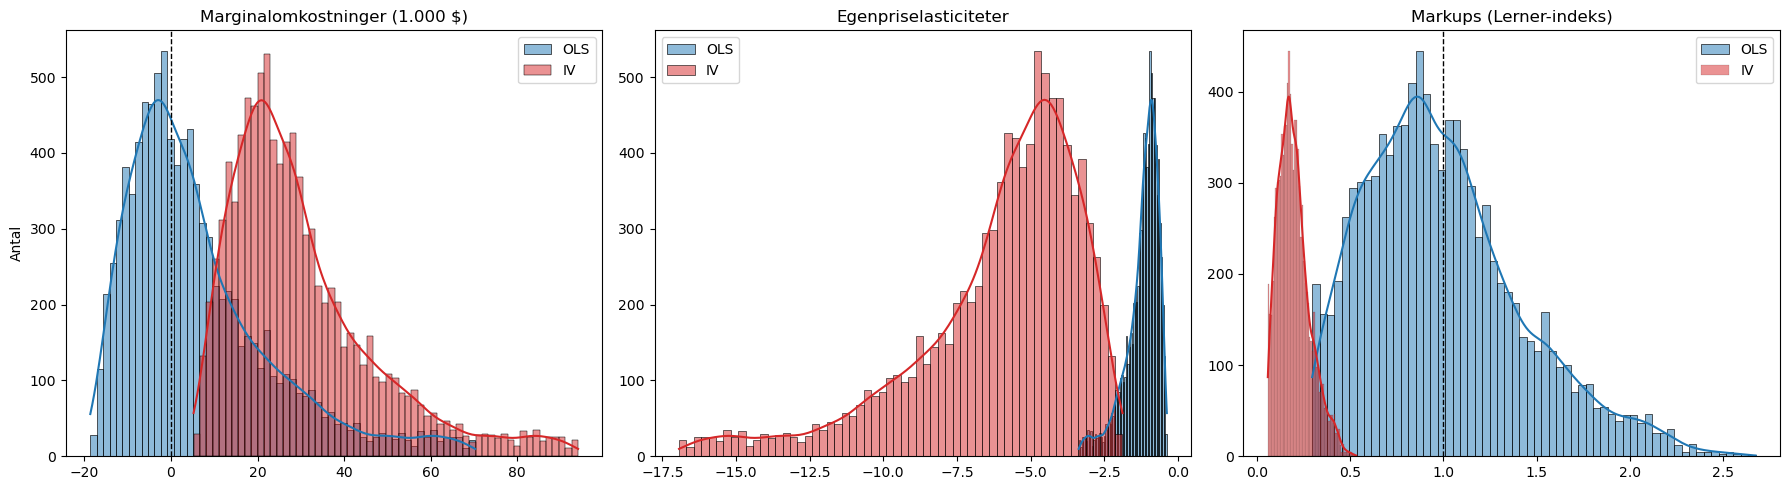

In [196]:
#3B - Illustration OLS vs. IV

import matplotlib.pyplot as plt
import seaborn as sns

figurer = [
    ('mc', 'Marginalomkostninger (1.000 $)'),
    ('e', 'Egenpriselasticiteter'),
    ('markup', 'Markups (Lerner-indeks)'),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (var, titel) in zip(axes, figurer):
    sns.histplot(df[f'{var}_OLS'], bins=60, kde=True, color='tab:blue',
                 alpha=0.5, label='OLS', ax=ax)
    sns.histplot(df[f'{var}_IV'], bins=60, kde=True, color='tab:red',
                 alpha=0.5, label='IV', ax=ax)
    ax.set_title(titel)
    ax.set_xlabel('')
    ax.set_ylabel('Antal' if var == 'mc' else '')
    ax.legend()

# Hjælpelinjer: mc = 0 og markup = 1 (grænser for, hvad der er økonomisk muligt)
axes[0].axvline(0, color='black', linestyle='--', linewidth=1)
axes[2].axvline(1, color='black', linestyle='--', linewidth=1)

fig.tight_layout()
plt.savefig('fig_3b_fordelinger.png', dpi=300, bbox_inches='tight')
plt.show()

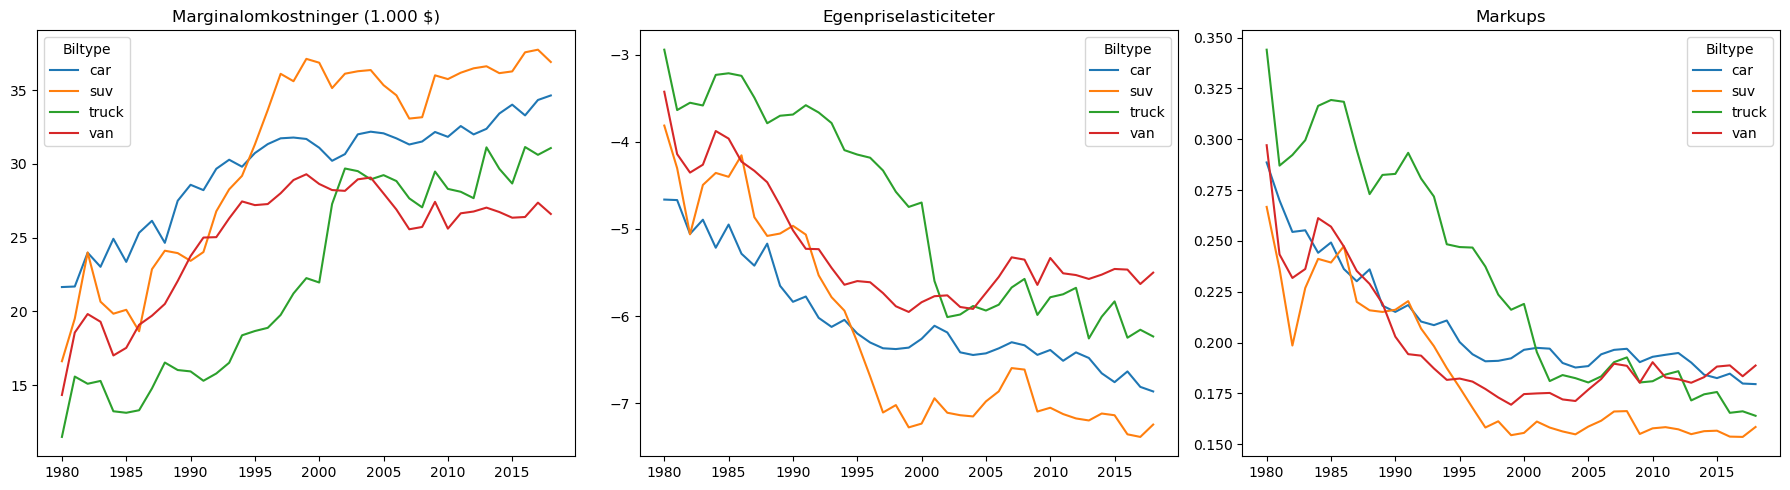

In [197]:
#3B - Udvikling over tid pr. biltype (IV)

import matplotlib.pyplot as plt
import seaborn as sns

# Gennemsnit pr. år og biltype
iv_year = df.groupby(['year', 'type'])[['mc_IV', 'e_IV', 'markup_IV']].mean().reset_index()

figurer = [
    ('mc_IV', 'Marginalomkostninger (1.000 $)'),
    ('e_IV', 'Egenpriselasticiteter'),
    ('markup_IV', 'Markups'),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (var, titel) in zip(axes, figurer):
    sns.lineplot(data=iv_year, x='year', y=var, hue='type', ax=ax)
    ax.set_title(titel)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.legend(title='Biltype')

fig.tight_layout()
plt.savefig('fig_3b_iv_tid.png', dpi=300, bbox_inches='tight')
plt.show()

In [198]:
#3C - Marginalomkostningsfunktion

# Make-dummies (genskabes, hvis de er blevet fjernet)
df = df.drop(columns=[c for c in df.columns if c.startswith('m_')])
make_dummies = pd.get_dummies(df['make'], prefix='m', drop_first=True, dtype=int)
df = pd.concat([df, make_dummies], axis=1)
brand = list(make_dummies.columns)

#Marginalomkostninger fra 3B
mc_IV = p - 1/(- alpha_hat_IV * (1-s))
df['mc_IV'] = mc_IV

#Log-transformation
df['log_mc'] = np.log(df['mc_IV'])

x_mc = ['const', 'RXR', 'log_hp', 'log_mpg', 'log_height', 'log_footprint', 'log_weight',
        'log_number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van'] + years + brand

X_mc = df[x_mc].values
y_mc = df['log_mc'].values

n = X_mc.shape[0]
k = X_mc.shape[1] - 1

gamma_mc = np.linalg.inv(X_mc.T @ X_mc) @ X_mc.T @ y_mc

residualer_mc = y_mc - X_mc @ gamma_mc
sigma2_mc = np.sum(residualer_mc**2) / (n - k - 1)
se_mc = np.sqrt(np.diag(sigma2_mc * np.linalg.inv(X_mc.T @ X_mc)))

# Koefficienter for RXR og produktkarakteristika (ikke dummies)
for navn, b, se in zip(x_mc, gamma_mc, se_mc):
    if not navn.startswith(('y_', 'm_')):
        print(f"{navn:18s} estimat = {b:8.4f}, std. fejl = {se:.4f}, t = {b/se:.2f}")

const              estimat =  -6.1841, std. fejl = 0.2561, t = -24.15
RXR                estimat =   0.1765, std. fejl = 0.0132, t = 13.33
log_hp             estimat =   0.4663, std. fejl = 0.0136, t = 34.28
log_mpg            estimat =   0.1115, std. fejl = 0.0157, t = 7.12
log_height         estimat =  -0.7765, std. fejl = 0.0382, t = -20.35
log_footprint      estimat =  -0.1368, std. fejl = 0.0342, t = -4.00
log_weight         estimat =   1.3618, std. fejl = 0.0291, t = 46.82
log_number_trims   estimat =  -0.0306, std. fejl = 0.0026, t = -11.82
releaseYear        estimat =  -0.0126, std. fejl = 0.0075, t = -1.67
yearsSinceDesign   estimat =  -0.0011, std. fejl = 0.0007, t = -1.47
sport              estimat =   0.1563, std. fejl = 0.0078, t = 19.96
EV                 estimat =   0.3525, std. fejl = 0.0251, t = 14.05
truck              estimat =  -0.1479, std. fejl = 0.0102, t = -14.55
suv                estimat =   0.0128, std. fejl = 0.0081, t = 1.58
van                estimat =  -0

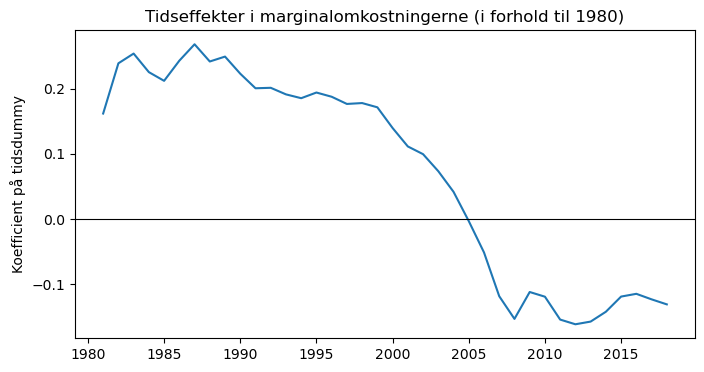

In [199]:
#3C - mc over tid

kappa = [(int(navn[2:]), b) for navn, b in zip(x_mc, gamma_mc) if navn.startswith('y_')]
aar, koef = zip(*kappa)

plt.figure(figsize=(8, 4))
plt.plot(aar, koef)
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Tidseffekter i marginalomkostningerne (i forhold til 1980)')
plt.ylabel('Koefficient på tidsdummy')
plt.savefig('fig_3c_tidseffekter.png', dpi=300, bbox_inches='tight')
plt.show()

In [200]:
#4C -  Scenarie 1

def simulate(n):

    ## Parameterværdier
    beta0 = 0.5
    beta1 = -0.1
    gamma0 = 0.25
    gamma1 = 1.0
    gamma2 = 1.0

    eta0 = (gamma0 - beta0) / (beta1 - gamma1)
    eta1 = gamma2 / (beta1 - gamma1)

    # Simuler data
    z  = np.random.normal(loc=0, scale=1, size=n)   # z ~ N(0,1)
    xi = np.random.normal(loc=0, scale=1, size=n)   # xi ~ N(0,1)
    v  = np.random.normal(loc=0, scale=1, size=n)   # v ~ N(0,1)

    u = (v - xi) / (beta1 - gamma1)
    p = eta0 + eta1*z + u
    y = beta0 + beta1*p + xi

    ## OLS: Cov(p, y) / Var(p)
    beta1_OLS = np.cov(p, y)[0, 1] / np.var(p, ddof=1)

    ## IV: Cov(z, y) / Cov(z, p)
    beta1_IV = np.cov(z, y)[0, 1] / np.cov(z, p)[0, 1]

    return beta1_OLS, beta1_IV


def monte_carlo(n, reps=500):
    np.random.seed(0)
    out = []

    for rep in range(reps):
        out.append(simulate(n))

    results = pd.DataFrame(out, columns=['beta1_OLS', 'beta1_IV'])

    return results


res = monte_carlo(n=500, reps=500)
print('Gennemsnit:\n', res.mean().round(5))
print('Bias:\n', (res.mean() - (-0.1)).round(5))
print('Varians:\n', res.var(ddof=1).round(5))

Gennemsnit:
 beta1_OLS    0.26753
beta1_IV    -0.10030
dtype: float64
Bias:
 beta1_OLS    0.36753
beta1_IV    -0.00030
dtype: float64
Varians:
 beta1_OLS   0.00056
beta1_IV    0.00236
dtype: float64


In [201]:
#4C -  Scenarie 2

def simulate(n):

    ## Parameterværdier
    beta0 = 0.5
    beta1 = -0.1
    gamma0 = 0.25
    gamma1 = 1.0
    gamma2 = 0.25

    eta0 = (gamma0 - beta0) / (beta1 - gamma1)
    eta1 = gamma2 / (beta1 - gamma1)

    # Simuler data
    z  = np.random.normal(loc=0, scale=1, size=n)   # z ~ N(0,1)
    xi = np.random.normal(loc=0, scale=1, size=n)   # xi ~ N(0,1)
    v  = np.random.normal(loc=0, scale=1, size=n)   # v ~ N(0,1)

    u = (v - xi) / (beta1 - gamma1)
    p = eta0 + eta1*z + u
    y = beta0 + beta1*p + xi

    ## OLS: Cov(p, y) / Var(p)
    beta1_OLS = np.cov(p, y)[0, 1] / np.var(p, ddof=1)

    ## IV: Cov(z, y) / Cov(z, p)
    beta1_IV = np.cov(z, y)[0, 1] / np.cov(z, p)[0, 1]

    return beta1_OLS, beta1_IV


def monte_carlo(n, reps=500):
    np.random.seed(0)
    out = []

    for rep in range(reps):
        out.append(simulate(n))

    results = pd.DataFrame(out, columns=['beta1_OLS', 'beta1_IV'])

    return results


res = monte_carlo(n=500, reps=500)
print('Gennemsnit:\n', res.mean().round(5))
print('Bias:\n', (res.mean() - (-0.1)).round(5))
print('Varians:\n', res.var(ddof=1).round(5))

Gennemsnit:
 beta1_OLS    0.43391
beta1_IV    -0.13065
dtype: float64
Bias:
 beta1_OLS    0.53391
beta1_IV    -0.03065
dtype: float64
Varians:
 beta1_OLS   0.00064
beta1_IV    0.05343
dtype: float64


In [202]:
#4C - Scenarie 3

def simulate(n):

    ## Parameterværdier
    beta0 = 0.5
    beta1 = -0.1
    gamma0 = 0.25
    gamma1 = 0.25
    gamma2 = 1.0

    eta0 = (gamma0 - beta0) / (beta1 - gamma1)
    eta1 = gamma2 / (beta1 - gamma1)

    # Simuler data
    z  = np.random.normal(loc=0, scale=1, size=n)   # z ~ N(0,1)
    xi = np.random.normal(loc=0, scale=1, size=n)   # xi ~ N(0,1)
    v  = np.random.normal(loc=0, scale=1, size=n)   # v ~ N(0,1)

    u = (v - xi) / (beta1 - gamma1)
    p = eta0 + eta1*z + u
    y = beta0 + beta1*p + xi

    ## OLS: Cov(p, y) / Var(p)
    beta1_OLS = np.cov(p, y)[0, 1] / np.var(p, ddof=1)

    ## IV: Cov(z, y) / Cov(z, p)
    beta1_IV = np.cov(z, y)[0, 1] / np.cov(z, p)[0, 1]

    return beta1_OLS, beta1_IV


def monte_carlo(n, reps=500):
    np.random.seed(0)
    out = []

    for rep in range(reps):
        out.append(simulate(n))

    results = pd.DataFrame(out, columns=['beta1_OLS', 'beta1_IV'])

    return results


res = monte_carlo(n=500, reps=500)
print('Gennemsnit:\n', res.mean().round(5))
print('Bias:\n', (res.mean() - (-0.1)).round(5))
print('Varians:\n', res.var(ddof=1).round(5))

Gennemsnit:
 beta1_OLS    0.01694
beta1_IV    -0.10010
dtype: float64
Bias:
 beta1_OLS    0.11694
beta1_IV    -0.00010
dtype: float64
Varians:
 beta1_OLS   0.00006
beta1_IV    0.00024
dtype: float64
